# Counterparty Risk: Exposure Simulation and CVA of an Interest Rate Swap

**Goal.** When a bank trades a swap with a client, it is exposed to the client defaulting
while the swap is worth money to the bank. The **Credit Valuation Adjustment (CVA)** is the
price of that risk, charged to the client and managed by the XVA desk. This project builds
the full chain for a €100m 10-year payer swap:

1. Simulate future rates (Hull-White, see project 09) and revalue the swap on every path
2. Exposure profiles: EE, PFE, EPE
3. Netting and collateral (CSA), and what they save
4. CVA, DVA, the CVA charge as a running spread, and **wrong-way risk**

$$\text{CVA} = (1-R)\sum_i \mathbb{E}\big[D(t_i)\,V(t_i)^+\big]\;\mathbb{P}\big(\tau \in (t_{i-1}, t_i]\big)$$

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("cva.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/15-counterparty-risk-cva")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cva import HullWhite, Swap, par_rate, swap_values, exposure_profile, collateralised, cva, dva, cva_running_spread

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
model = HullWhite(a=0.05, sigma=0.009)
times = np.round(np.arange(0, 10 + 1e-9, 1 / 26), 10)             # every two weeks for 10 years
x, disc = model.simulate(times, 20_000, seed=1)
K = par_rate(model.curve, 10)
payer = Swap(100e6, K, 10, pay_fixed=True)
V = swap_values(model, payer, times, x)
print(f"10Y par rate {K:.3%}; {x.shape[0]:,} paths x {len(times)} dates; swap value today {V[:, 0].mean():,.0f} EUR")

10Y par rate 2.624%; 20,000 paths x 261 dates; swap value today 0 EUR


## 1. Future values of the swap

The swap is worth zero today, but its future value spreads out as rates move, then
shrinks back to zero as coupons are paid: the classic **diffusion vs amortisation** shape.

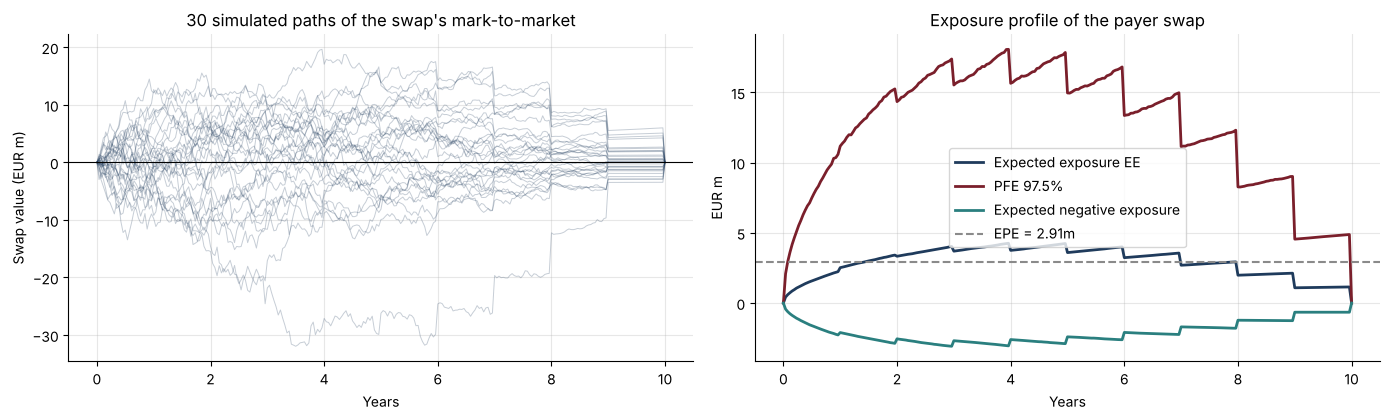

Peak PFE: 18.1m at 4.0 years (18.1% of notional)


In [2]:
prof = exposure_profile(V)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for i in range(30):
    axes[0].plot(times, V[i] / 1e6, color=NAVY, alpha=0.25, lw=0.7)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="Years", ylabel="Swap value (EUR m)", title="30 simulated paths of the swap's mark-to-market")
axes[1].plot(times, prof["EE"] / 1e6, color=NAVY, lw=2, label="Expected exposure EE")
axes[1].plot(times, prof["PFE"] / 1e6, color=BORDEAUX, lw=2, label="PFE 97.5%")
axes[1].plot(times, prof["ENE"] / 1e6, color=TEAL, lw=2, label="Expected negative exposure")
axes[1].axhline(prof["EPE"] / 1e6, color=GREY, ls="--", label=f"EPE = {prof['EPE'] / 1e6:.2f}m")
axes[1].set(xlabel="Years", ylabel="EUR m", title="Exposure profile of the payer swap"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/exposure_profile.png", dpi=150); plt.show()
print(f"Peak PFE: {prof['PFE'].max() / 1e6:.1f}m at {times[prof['PFE'].argmax()]:.1f} years ({prof['PFE'].max() / payer.notional:.1%} of notional)")

The payer swap's expected exposure is larger than its negative exposure: the curve is
upward sloping, so the floating rates the bank will receive are expected to rise above
the fixed rate it pays.

## 2. Netting and collateral

- **Netting:** if the client also has a 5-year receiver swap with the bank, the two values
  offset each other in default (one netting set under an ISDA agreement).
- **Collateral (CSA):** the client posts collateral equal to the swap value above a threshold.
  The bank is still exposed during the **margin period of risk** (10 business days here):
  the time to notice the default, stop receiving collateral and close out the trades.

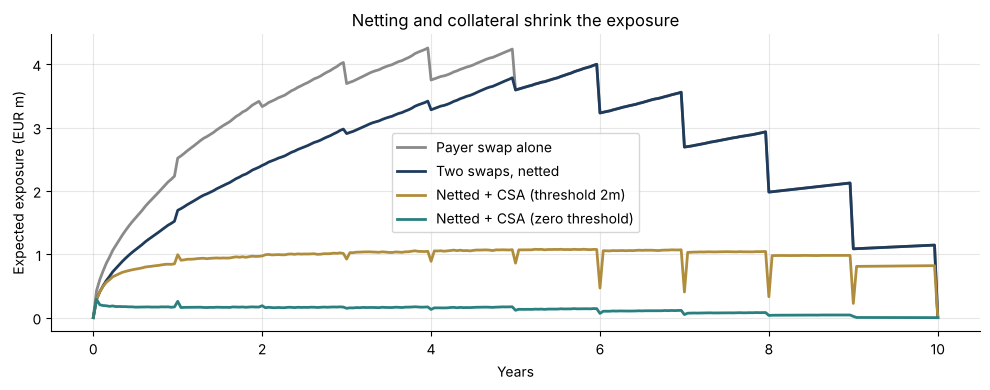

,EPE (EUR m),Peak PFE (EUR m),CVA (EUR k)
Payer swap alone,2.91,18.06,272.34
"Two swaps, no netting",3.18,NaN,NaN
"Two swaps, netted",2.55,16.81,233.69
Netted + CSA (threshold 2m),0.96,3.33,89.16
Netted + CSA (zero threshold),0.12,1.50,11.88


In [3]:
receiver = swap_values(model, Swap(60e6, par_rate(model.curve, 5), 5, pay_fixed=False), times, x)
netted = V + receiver
cases = {"Payer swap alone": V, "Two swaps, no netting": None, "Two swaps, netted": netted,
         "Netted + CSA (threshold 2m)": collateralised(netted, times, threshold=2e6, mta=0.25e6),
         "Netted + CSA (zero threshold)": collateralised(netted, times, threshold=0.0)}
rows = {}
for name, vals in cases.items():
    if vals is None:
        epe = exposure_profile(V)["EPE"] + exposure_profile(receiver)["EPE"]
        rows[name] = {"EPE (EUR m)": epe / 1e6}
        continue
    p = exposure_profile(vals)
    rows[name] = {"EPE (EUR m)": p["EPE"] / 1e6, "Peak PFE (EUR m)": p["PFE"].max() / 1e6,
                  "CVA (EUR k)": cva(vals, disc, times, hazard=0.02) / 1e3}
table = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(10, 4))
for (name, vals), c in zip([("Payer swap alone", V), ("Two swaps, netted", netted),
                            ("Netted + CSA (threshold 2m)", cases["Netted + CSA (threshold 2m)"]),
                            ("Netted + CSA (zero threshold)", cases["Netted + CSA (zero threshold)"])], [GREY, NAVY, GOLD, TEAL]):
    ax.plot(times, exposure_profile(vals)["EE"] / 1e6, color=c, lw=2, label=name)
ax.set(xlabel="Years", ylabel="Expected exposure (EUR m)", title="Netting and collateral shrink the exposure"); ax.legend()
plt.tight_layout(); plt.savefig("images/netting_collateral.png", dpi=150); plt.show()
table.round(2)

## 3. CVA, DVA and the charge to the client

The client's credit risk is a hazard rate taken from its CDS spread ($\lambda \approx s/(1-R)$).
**DVA** is the mirror image: the value of the bank's own default to the bank. The CVA is
turned into a running spread that the salesperson adds to the swap rate.

In [4]:
rows = []
for spread_bp in [50, 100, 200, 400]:
    lam = spread_bp * 1e-4 / 0.6
    c = cva(V, disc, times, lam)
    rows.append({"Client CDS (bp)": spread_bp, "CVA (EUR k)": c / 1e3,
                 "CVA as running spread (bp/yr)": cva_running_spread(c, model.curve, 10, payer.notional, lam)})
charges = pd.DataFrame(rows).set_index("Client CDS (bp)")
own_dva = dva(V, disc, times, own_hazard=60e-4 / 0.6)
print(f"Bank's DVA on this swap (own spread 60 bp): {own_dva / 1e3:,.0f}k EUR")
charges.round(2)

Bank's DVA on this swap (own spread 60 bp): 113k EUR


,CVA (EUR k),CVA as running spread (bp/yr)
Client CDS (bp),,
50,119.45,1.43
100,230.28,2.88
200,428.46,5.82
400,745.07,11.91


## 4. Wrong-way risk

CVA assumes exposure and default are independent. **Wrong-way risk** is when they are not:
the client is more likely to default precisely when the swap is worth a lot to the bank.
For a payer swap, exposure is high when rates rise; a highly indebted client paying
floating rates is exactly the kind of counterparty that suffers then. We let the default
intensity depend on the rate factor, $\lambda_t = \lambda\,e^{\beta z_t - \beta^2/2}$, which keeps
the average default probability unchanged.

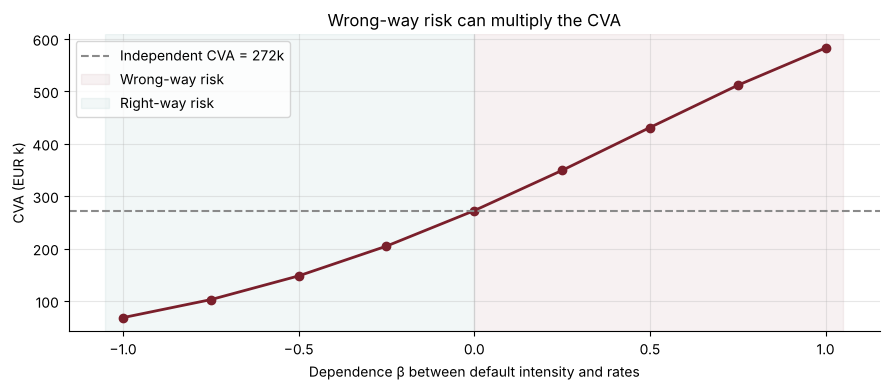

CVA with beta = +1: 2.1x the independent CVA; with beta = -1: 0.3x


In [5]:
betas = np.linspace(-1.0, 1.0, 9)
base = cva(V, disc, times, 0.02)
wwr = [cva(V, disc, times, 0.02, wwr_beta=b, x=x) for b in betas]
plt.figure(figsize=(9, 4))
plt.plot(betas, np.array(wwr) / 1e3, "o-", color=BORDEAUX, lw=2)
plt.axhline(base / 1e3, color=GREY, ls="--", label=f"Independent CVA = {base / 1e3:,.0f}k")
plt.axvspan(0, 1.05, color=BORDEAUX, alpha=0.06, label="Wrong-way risk")
plt.axvspan(-1.05, 0, color=TEAL, alpha=0.06, label="Right-way risk")
plt.xlabel("Dependence β between default intensity and rates"); plt.ylabel("CVA (EUR k)"); plt.legend()
plt.title("Wrong-way risk can multiply the CVA")
plt.tight_layout(); plt.savefig("images/wrong_way_risk.png", dpi=150); plt.show()
print(f"CVA with beta = +1: {wwr[-1] / base:.1f}x the independent CVA; with beta = -1: {wwr[0] / base:.1f}x")

## Conclusions
- The exposure of a 10-year swap peaks after about 4 years, with a 97.5% PFE of about 18%
  of notional, and a CVA of about €270k for a client with a 120 bp CDS spread.
- Netting and collateral cut the expected exposure and the CVA dramatically. With a
  zero-threshold CSA, only the 10-day margin period of risk remains.
- CVA grows almost linearly with the client's spread: 1.4 bp per year of running spread for
  a 50 bp name, 12 bp for a 400 bp name. Wrong-way risk doubles it (β = 1), which is why
  regulators require specific treatment of these trades.
- **Next steps:** FVA and MVA, CVA sensitivities and hedging with CDS, SA-CCR exposure,
  American Monte Carlo for callable trades.